# Word Frequency

Berapa kali tiap kata muncul dalam sebuah teks? Menghitung frekuensi kata adalah dasar pencarian, pengurutan, dan analisis makna teks.
Notebook ini mengerjakan [Word Frequency](https://github.com/florinpop17/app-ideas/blob/master/Projects/1-Beginner/Word-Frequency-App.md) dari app-ideas.

Logikanya ada di `wordfreq.py` (dengan unit test): `tokenize`, `count_words`, `html_to_text`, dan `fetch_text`.
Notebook ini memakainya, menampilkan tabel dan grafik, lalu menganalisis **teks nyata**: README semua project di repo ini sendiri.

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from wordfreq import MAX_CHARS, STOPWORDS, count_words, html_to_text, tokenize

plt.rcParams.update({"figure.figsize": (7, 4.2), "axes.spines.top": False, "axes.spines.right": False})

## 1. Apa itu "kata"?

Pertanyaan pertama bukan menghitung, tetapi **memotong teks jadi kata**. Aturan di sini: deretan huruf (termasuk huruf beraksen),
boleh berisi apostrof atau tanda hubung di tengah; huruf besar/kecil dianggap sama; angka dan tanda baca dibuang.

In [2]:
contoh = "Don't e-mail Zoë! Café, café... anak-anak main 2 kali; snake_case."
print(tokenize(contoh))

["don't", 'e-mail', 'zoë', 'café', 'café', 'anak-anak', 'main', 'kali', 'snake', 'case']


## 2. Menghitung, dan mengurutkan dari yang paling sering

Jumlah yang sama diurutkan menurut abjad supaya hasilnya selalu sama setiap kali dijalankan.

In [3]:
teks = '''
Belajar pemrograman itu seperti belajar bahasa. Setiap hari kita menulis sedikit kode, membaca kode orang lain,
dan memperbaiki kesalahan. Kesalahan bukan musuh: kesalahan adalah guru yang paling jujur.
Kode yang baik mudah dibaca, dan kode yang mudah dibaca mudah diperbaiki.
'''
hasil = count_words(teks)
tabel = pd.DataFrame(hasil, columns=["kata", "jumlah"])
tabel.index = tabel.index + 1
print(f"{len(tabel)} kata unik, {tabel.jumlah.sum()} kata seluruhnya")
tabel.head(10)

28 kata unik, 40 kata seluruhnya


,kata,jumlah
1,kode,4
2,kesalahan,3
3,mudah,3
4,yang,3
5,belajar,2
6,dan,2
7,dibaca,2
8,adalah,1
9,bahasa,1
10,baik,1


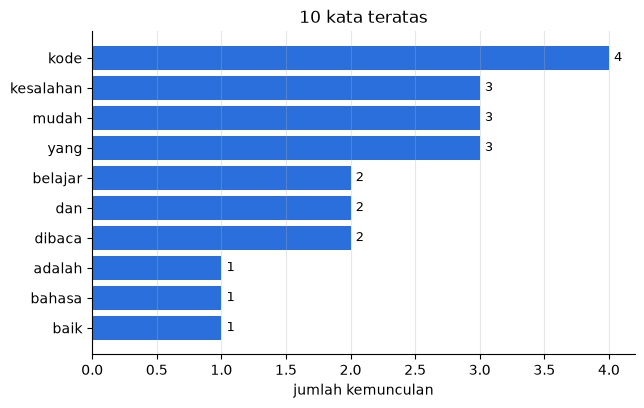

In [4]:
def grafik_batang(hasil, judul, top=10):
    kata, jumlah = zip(*hasil[:top])
    fig, ax = plt.subplots()
    ax.barh(kata[::-1], jumlah[::-1], color="#2a6fdb")
    ax.set(title=judul, xlabel="jumlah kemunculan")
    for y, n in enumerate(jumlah[::-1]):
        ax.text(n + max(jumlah) * 0.01, y, str(n), va="center", fontsize=9)
    ax.grid(axis="x", alpha=.3)
    plt.show()

grafik_batang(hasil, "10 kata teratas")

Kata seperti *yang*, *dan*, *di*, *itu* mendominasi tetapi tidak banyak bercerita tentang isi teks.
Daftar kata umum (**stopwords**) bisa dibuang untuk melihat kata yang bermakna. Perhatikan bagaimana urutan teratas berubah.

In [5]:
tanpa_umum = count_words(teks, stopwords=STOPWORDS["id"])
print("Sebelum:", hasil[:5])
print("Sesudah:", tanpa_umum[:5])

Sebelum: [('kode', 4), ('kesalahan', 3), ('mudah', 3), ('yang', 3), ('belajar', 2)]
Sesudah: [('kode', 4), ('kesalahan', 3), ('mudah', 3), ('belajar', 2), ('dibaca', 2)]


## 3. Bubble chart

Luas lingkaran sebanding dengan jumlah kemunculan. Lingkaran ditempatkan satu per satu dari yang terbesar, bergerak dalam spiral sampai tidak bertabrakan.

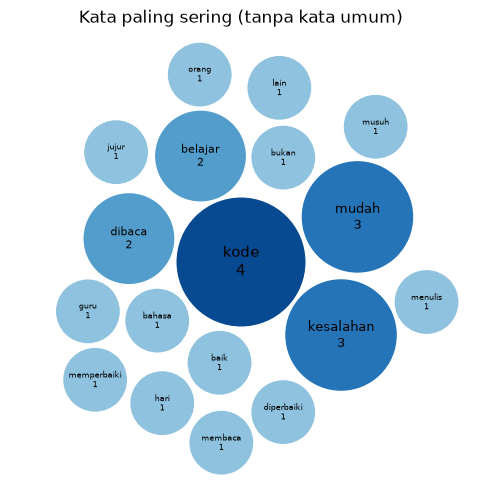

In [6]:
def tata_lingkaran(radii, jarak=0.03):
    ditempatkan = []
    for r in radii:
        sudut = jarak_dari_pusat = 0.0
        while True:
            x, y = jarak_dari_pusat * math.cos(sudut), jarak_dari_pusat * math.sin(sudut)
            if all((x - px) ** 2 + (y - py) ** 2 >= (r + pr + jarak) ** 2 for px, py, pr in ditempatkan):
                ditempatkan.append((x, y, r))
                break
            sudut += 0.25
            jarak_dari_pusat += 0.004
    return ditempatkan

def bubble_chart(hasil, judul, top=25):
    data = hasil[:top]
    radii = [math.sqrt(n) for _, n in data]            # luas ~ jumlah
    skala = 1 / max(radii)
    posisi = tata_lingkaran([r * skala for r in radii])
    fig, ax = plt.subplots(figsize=(7, 6))
    for (x, y, r), (kata, n) in zip(posisi, data):
        ax.add_patch(plt.Circle((x, y), r, color=plt.cm.Blues(0.25 + 0.65 * n / data[0][1]), ec="white"))
        ax.text(x, y, f"{kata}\n{n}", ha="center", va="center", fontsize=max(5, 11 * r / posisi[0][2]), color="black")
    batas = max(max(abs(x) + r, abs(y) + r) for x, y, r in posisi) * 1.05
    ax.set(xlim=(-batas, batas), ylim=(-batas, batas), title=judul, aspect="equal")
    ax.axis("off")
    plt.show()

bubble_chart(tanpa_umum, "Kata paling sering (tanpa kata umum)", top=18)

## 4. Teks nyata: README semua project di repo ini

Batas 2048 karakter pada spesifikasi berlaku untuk **kotak isian**. Untuk teks yang lebih besar, `count_words(..., max_chars=None)` tidak memakai batas itu.

In [7]:
import re

akar = Path("../..").resolve()
berkas = sorted([akar / "README.md", *akar.glob("1-beginner/*/README.md")])
mentah = "\n".join(p.read_text(encoding="utf-8") for p in berkas)

# Hanya prosa: buang blok kode, kode sebaris, dan tautan supaya contoh kode tidak ikut terhitung.
korpus = re.sub(r"```.*?```", " ", mentah, flags=re.S)
korpus = re.sub(r"`[^`\n]*`", " ", korpus)
korpus = re.sub(r"\]\([^)]*\)|https?://\S+", " ", korpus)
print(f"{len(berkas)} berkas README, {len(korpus):,} karakter prosa (batas isian: {MAX_CHARS})")

try:
    count_words(korpus)             # dengan batas bawaan
except ValueError as e:
    print("Dengan batas bawaan:", e)

semua = count_words(korpus, max_chars=None)
bermakna = count_words(korpus, max_chars=None, stopwords=STOPWORDS["id"] | STOPWORDS["en"])
print(f"{sum(n for _, n in semua):,} kata, {len(semua):,} kata unik")

23 berkas README, 23,625 karakter prosa (batas isian: 2048)
Dengan batas bawaan: Teks terlalu panjang: 23625 karakter (maksimal 2048).
3,086 kata, 982 kata unik


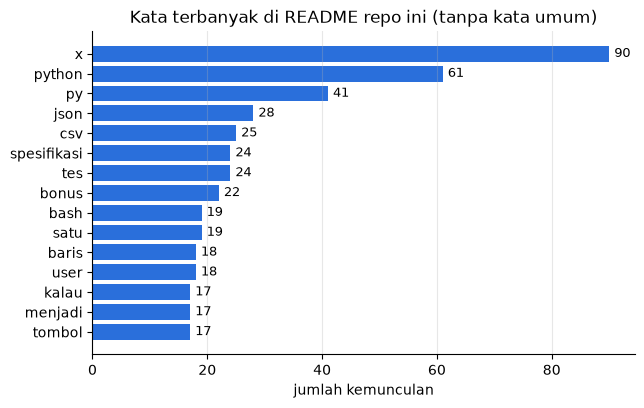

In [8]:
grafik_batang(bermakna, "Kata terbanyak di README repo ini (tanpa kata umum)", top=15)

## 5. Hukum Zipf

Pada hampir semua teks alami, frekuensi sebuah kata berbanding terbalik dengan peringkatnya: kata peringkat 1 muncul kira-kira dua kali lebih sering dari peringkat 2, tiga kali dari peringkat 3, dan seterusnya.
Di grafik log-log, itu terlihat sebagai garis lurus miring turun dengan kemiringan sekitar $-1$.

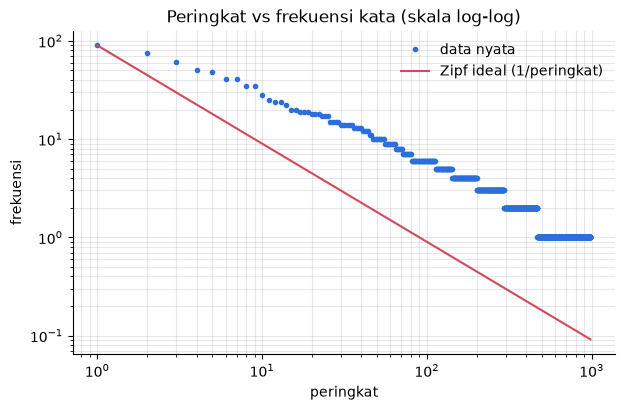

Sepuluh kata teratas dan perkiraan Zipf:
  #1  x          nyata   90   Zipf    90
  #2  dan        nyata   76   Zipf    45
  #3  python     nyata   61   Zipf    30
  #4  di         nyata   50   Zipf    22
  #5  tidak      nyata   48   Zipf    18
  #6  py         nyata   41   Zipf    15
  #7  yang       nyata   41   Zipf    13
  #8  atau       nyata   35   Zipf    11
  #9  dengan     nyata   35   Zipf    10
  #10 json       nyata   28   Zipf     9

Kemiringan log-log (200 peringkat teratas): -0.69  (Zipf ideal: -1.00)
Kata yang hanya muncul sekali: 52% dari kata unik


In [9]:
frekuensi = [n for _, n in semua]
peringkat = range(1, len(frekuensi) + 1)

fig, ax = plt.subplots()
ax.loglog(peringkat, frekuensi, ".", color="#2a6fdb", label="data nyata")
ax.loglog(peringkat, [frekuensi[0] / r for r in peringkat], "-", color="#d1495b", label="Zipf ideal (1/peringkat)")
ax.set(title="Peringkat vs frekuensi kata (skala log-log)", xlabel="peringkat", ylabel="frekuensi")
ax.legend(frameon=False)
ax.grid(alpha=.3, which="both")
plt.show()

print("Sepuluh kata teratas dan perkiraan Zipf:")
for r in range(1, 11):
    kata, n = semua[r - 1]
    print(f"  #{r:<2} {kata:<10} nyata {n:>4}   Zipf {frekuensi[0] / r:>5.0f}")

# kemiringan garis pada skala log-log, kuadrat terkecil sederhana atas 200 peringkat teratas
xs = [math.log(r) for r in range(1, 201)]
ys = [math.log(frekuensi[r - 1]) for r in range(1, 201)]
mx, my = sum(xs) / len(xs), sum(ys) / len(ys)
kemiringan = sum((x - mx) * (y - my) for x, y in zip(xs, ys)) / sum((x - mx) ** 2 for x in xs)
sekali = sum(1 for n in frekuensi if n == 1) / len(frekuensi)
print(f"\nKemiringan log-log (200 peringkat teratas): {kemiringan:.2f}  (Zipf ideal: -1.00)")
print(f"Kata yang hanya muncul sekali: {sekali:.0%} dari kata unik")

**Hasil di korpus ini** (angka tepatnya ada di keluaran di atas): bentuknya garis turun yang jelas, dan lebih dari separuh kata unik hanya muncul sekali (ciri khas Zipf), tetapi kemiringannya **lebih landai dari −1** dan beberapa peringkat teratas menyimpang jauh. Wajar:
korpusnya kecil (beberapa ribu kata), sangat teknis, dan dipenuhi simbol seperti `x` dari rumus. Hukum Zipf paling rapi pada teks yang besar dan wajar.
Pelajarannya: hukum statistik adalah pola, bukan rumus pasti, dan **mengukurnya** lebih jujur daripada menganggapnya benar.

## 6. Halaman web (bonus)

`fetch_text(url)` mengunduh halaman lalu membuang script, style, dan kepala dokumen, dan mendekode entitas HTML sebelum dihitung.
Agar notebook ini tidak bergantung pada internet, bagian ekstraksinya diperlihatkan dengan HTML buatan sendiri:

In [10]:
halaman = '''
<html><head><title>Judul tidak dihitung</title><style>p {color: red}</style></head>
<body><h1>Kucing &amp; Anjing</h1><script>var rahasia = "tidak dihitung";</script>
<p>Kucing suka tidur. Anjing suka berlari. Kucing <b>sangat</b> suka tidur.</p></body></html>
'''
print(html_to_text(halaman))
print(count_words(html_to_text(halaman), stopwords=STOPWORDS["id"])[:4])

Kucing & Anjing Kucing suka tidur. Anjing suka berlari. Kucing sangat suka tidur.
[('kucing', 3), ('suka', 3), ('anjing', 2), ('tidur', 2)]


Dari terminal, dengan halaman sungguhan: `python wordfreq.py --url https://example.com --top 10`.

## Rangkuman

- Memotong teks menjadi kata adalah keputusan desain (huruf beraksen, apostrof, tanda hubung, angka), bukan sekadar `split()`.
- Urutan yang stabil (jumlah turun, lalu abjad) membuat hasil bisa diuji dan diulang.
- Kata umum mendominasi hitungan; membuangnya mengungkap isi teks.
- Frekuensi kata kira-kira mengikuti pola Zipf: sedikit kata sangat sering, sebagian besar kata unik hanya muncul sekali. Di korpus kecil ini polanya lebih landai dari idealnya.